In [16]:

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


In [17]:

flights_07 = pd.read_csv("flight_delays_2025_07.csv")
flights_08 = pd.read_csv("flight_delays_2025_08.csv")
flights_09 = pd.read_csv("flight_delays_2025_09.csv")
flights_10 = pd.read_csv("flight_delays_2025_10.csv")
flights_11 = pd.read_csv("flight_delays_2025_11.csv")
flights_12 = pd.read_csv("flight_delays_2025_12.csv")



All 6 CSV files loaded.


In [18]:

flights = pd.concat([
    flights_07,
    flights_08,
    flights_09,
    flights_10,
    flights_11,
    flights_12
], ignore_index=True)

print("Total Flights:", len(flights))

flights.head()


Total Flights: 3554943


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,OriginCityName,...,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025,3,7,23,3,2025-07-23,AA,969,MIA,"Miami, FL",...,0.0,130.0,128.0,91.0,650.0,NaN,NaN,NaN,NaN,NaN
1,2025,3,7,24,4,2025-07-24,AA,969,MIA,"Miami, FL",...,0.0,130.0,119.0,94.0,650.0,0.0,0.0,0.0,0.0,74.0
2,2025,3,7,25,5,2025-07-25,AA,969,MIA,"Miami, FL",...,0.0,130.0,116.0,89.0,650.0,NaN,NaN,NaN,NaN,NaN
3,2025,3,7,26,6,2025-07-26,AA,969,MIA,"Miami, FL",...,0.0,130.0,145.0,87.0,650.0,NaN,NaN,NaN,NaN,NaN
4,2025,3,7,27,7,2025-07-27,AA,969,MIA,"Miami, FL",...,0.0,130.0,113.0,94.0,650.0,NaN,NaN,NaN,NaN,NaN


In [19]:

flights = flights.dropna(subset=["ArrDel15"])

features = [
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "CRSDepTime",
    "CRSArrTime",
    "CRSElapsedTime",
    "Distance"
]

flights = flights.dropna(subset=features)

print("Flights with known arrival delay:", len(flights))

flights.groupby("ArrDel15").size()


Flights with known arrival delay: 3493662


,0
ArrDel15,
0.0,2700337
1.0,793325


In [21]:

X = flights[features]
y = flights["ArrDel15"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=31337
)

print(X_train.shape, X_test.shape)


(2794929, 7) (698733, 7)


In [22]:

def flight_accuracy(model, X, y):
    predicted_delays = model.predict(X)

    correct_delays = [
        1 if predicted_delay == actual_delay else 0
        for predicted_delay, actual_delay in zip(predicted_delays, y)
    ]

    return sum(correct_delays) / len(correct_delays)


tree_rows = []

for depth in tqdm(range(1, 11)):
    model = DecisionTreeClassifier(max_depth=depth, random_state=31337)
    model.fit(X_train, y_train)

    train_acc = flight_accuracy(model, X_train, y_train)
    test_acc = flight_accuracy(model, X_test, y_test)

    tree_rows.append({
        "depth": depth,
        "train_acc": train_acc,
        "test_acc": test_acc
    })

tree_df = pd.DataFrame(tree_rows)

tree_df


  0%|          | 0/10 [00:00<?, ?it/s]

,depth,train_acc,test_acc
0,1,0.773036,0.772478
1,2,0.773036,0.772478
2,3,0.773036,0.772478
3,4,0.773036,0.772478
4,5,0.773833,0.773202
5,6,0.774429,0.773806
6,7,0.775420,0.774795
7,8,0.775791,0.774966
8,9,0.776474,0.775571
9,10,0.777603,0.775957


<Axes: xlabel='Max Depth', ylabel='Accuracy'>

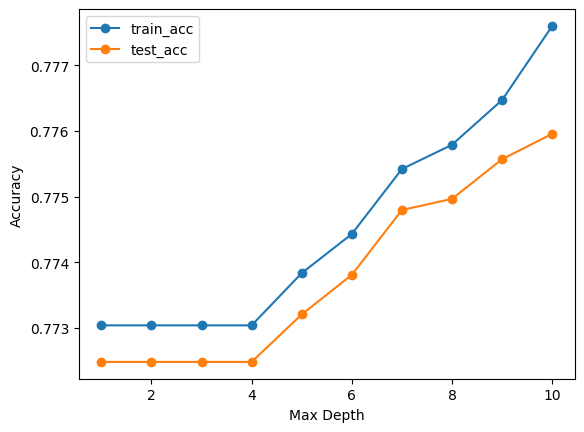

In [23]:

tree_df.plot(
    x="depth",
    y=["train_acc", "test_acc"],
    marker="o",
    ylabel="Accuracy",
    xlabel="Max Depth"
)


In [29]:

predicted_delays = model.predict(X_test)

wrong_rows = []

for flight_id, predicted_delay, actual_delay in zip(X_test.index, predicted_delays, y_test):
    if predicted_delay != actual_delay:
        wrong_rows.append({
            "flight_id": flight_id,
            "actual": actual_delay,
            "predicted": predicted_delay
        })

wrong_df = pd.DataFrame(wrong_rows)

wrong_df.head(5)


,flight_id,actual,predicted
0,1852509,1.0,0.0
1,2698423,1.0,0.0
2,199343,1.0,0.0
3,3204538,1.0,0.0
4,435343,1.0,0.0


In [30]:
wrong_flight_ids = wrong_df.head(5)["flight_id"]

flights.loc[wrong_flight_ids, [
    "FlightDate",
    "Reporting_Airline",
    "CRSDepTime",
    "CRSArrTime",
    "Distance",
    "ArrDelay",
    "ArrDel15"
]]

,FlightDate,Reporting_Airline,CRSDepTime,CRSArrTime,Distance,ArrDelay,ArrDel15
1852509,2025-10-10,AA,1044,1307,2133.0,59.0,1.0
2698423,2025-11-03,AA,1337,1750,1389.0,60.0,1.0
199343,2025-07-29,OO,1614,1732,726.0,17.0,1.0
3204538,2025-12-30,F9,600,853,862.0,21.0,1.0
435343,2025-07-22,WN,1835,2125,612.0,121.0,1.0
